In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pyarrow

In [18]:
df = pd.read_excel("Sample - Superstore 2019.xls")

In [19]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Row ID          9994 non-null   int64         
 1   Order ID        9994 non-null   str           
 2   Order Date      9994 non-null   datetime64[us]
 3   Ship Date       9994 non-null   datetime64[us]
 4   Ship Mode       9994 non-null   str           
 5   Customer ID     9994 non-null   str           
 6   Customer Name   9994 non-null   str           
 7   Segment         9994 non-null   str           
 8   Country/Region  9994 non-null   str           
 9   City            9994 non-null   str           
 10  State           9994 non-null   str           
 11  Postal Code     9983 non-null   float64       
 12  Region          9994 non-null   str           
 13  Product ID      9994 non-null   str           
 14  Category        9994 non-null   str           
 15  Sub-Category   

In [20]:
df.describe()

,Row ID,Order Date,Ship Date,Postal Code,Sales,Quantity,Discount,Profit
count,9994.000000,9994,9994,9983.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,4997.500000,2018-04-30 10:03:51.979187,2018-05-04 09:03:29.645787,55245.233297,229.858001,3.789574,0.156203,28.656896
min,1.000000,2016-01-03 00:00:00,2016-01-07 00:00:00,1040.000000,0.444000,1.000000,0.000000,-6599.978000
25%,2499.250000,2017-05-23 00:00:00,2017-05-27 00:00:00,23223.000000,17.280000,2.000000,0.000000,1.728750
50%,4997.500000,2018-06-26 00:00:00,2018-06-29 00:00:00,57103.000000,54.490000,3.000000,0.200000,8.666500
75%,7495.750000,2019-05-14 00:00:00,2019-05-18 00:00:00,90008.000000,209.940000,5.000000,0.200000,29.364000
max,9994.000000,2019-12-30 00:00:00,2020-01-05 00:00:00,99301.000000,22638.480000,14.000000,0.800000,8399.976000
std,2885.163629,NaN,NaN,32038.715955,623.245101,2.225110,0.206452,234.260108


In [21]:
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2018-152156,2018-11-08,2018-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2018-152156,2018-11-08,2018-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2018-138688,2018-06-12,2018-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2017-108966,2017-10-11,2017-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2017-108966,2017-10-11,2017-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [22]:
df_raw = df.copy()

In [23]:
df_raw.shape

(9994, 21)

In [24]:
df_raw.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2018-152156,2018-11-08,2018-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2018-152156,2018-11-08,2018-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2018-138688,2018-06-12,2018-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2017-108966,2017-10-11,2017-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2017-108966,2017-10-11,2017-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [25]:
columns_list = ["Category", "City", "Sales", "Customer ID"]
df_raw[columns_list].head()

,Category,City,Sales,Customer ID
0,Furniture,Henderson,261.9600,CG-12520
1,Furniture,Henderson,731.9400,CG-12520
2,Office Supplies,Los Angeles,14.6200,DV-13045
3,Furniture,Fort Lauderdale,957.5775,SO-20335
4,Office Supplies,Fort Lauderdale,22.3680,SO-20335


In [26]:
mask = df_raw["Postal Code"].isnull() == True
df_raw[mask][["Country/Region", "City", "State", "Region"]]

,Country/Region,City,State,Region
2234,United States,Burlington,Vermont,East
5274,United States,Burlington,Vermont,East
8798,United States,Burlington,Vermont,East
9146,United States,Burlington,Vermont,East
9147,United States,Burlington,Vermont,East
9148,United States,Burlington,Vermont,East
9386,United States,Burlington,Vermont,East
9387,United States,Burlington,Vermont,East
9388,United States,Burlington,Vermont,East
9389,United States,Burlington,Vermont,East


In [27]:
import pandas as pd

df_raw = pd.read_excel("Sample - Superstore 2019.xls")

df_raw['Postal Code'] = df_raw['Postal Code'].astype('object')

df_raw.loc[df_raw['City'] == 'Burlington', 'Postal Code'] = "05401"

print("Missing values in Postal Code:", df_raw['Postal Code'].isnull().sum())
display(df_raw[df_raw['City'] == 'Burlington'][['City', 'Postal Code']].head())

Missing values in Postal Code: 0


,City,Postal Code
683,Burlington,05401
684,Burlington,05401
1008,Burlington,05401
1038,Burlington,05401
1039,Burlington,05401


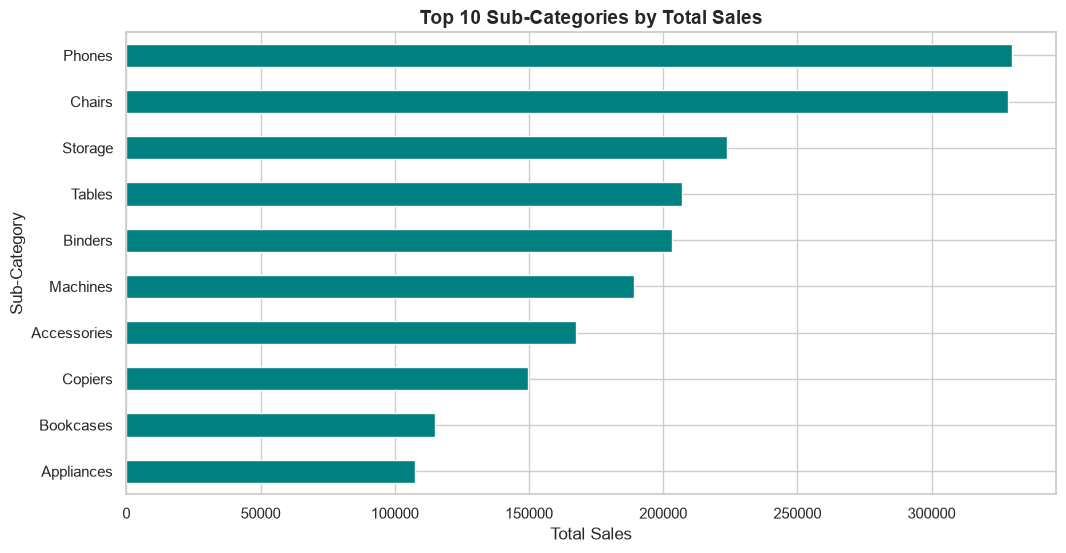

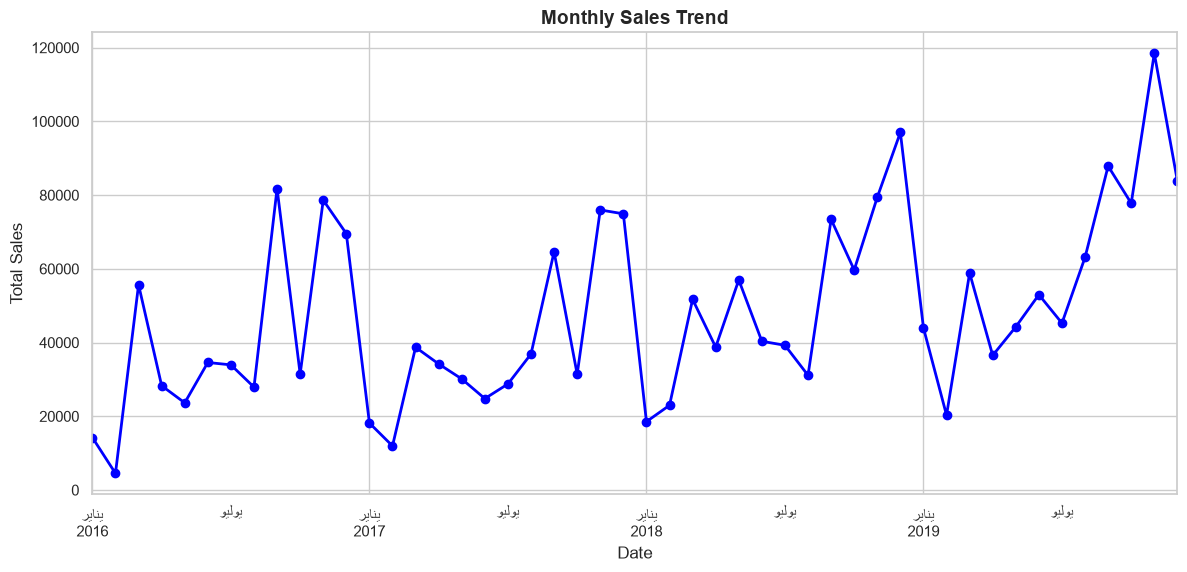

C:\Users\اذكر الله\AppData\Local\Temp\ipykernel_15244\2462153251.py:36: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_raw, x='Category', y='Profit', palette='Set2')


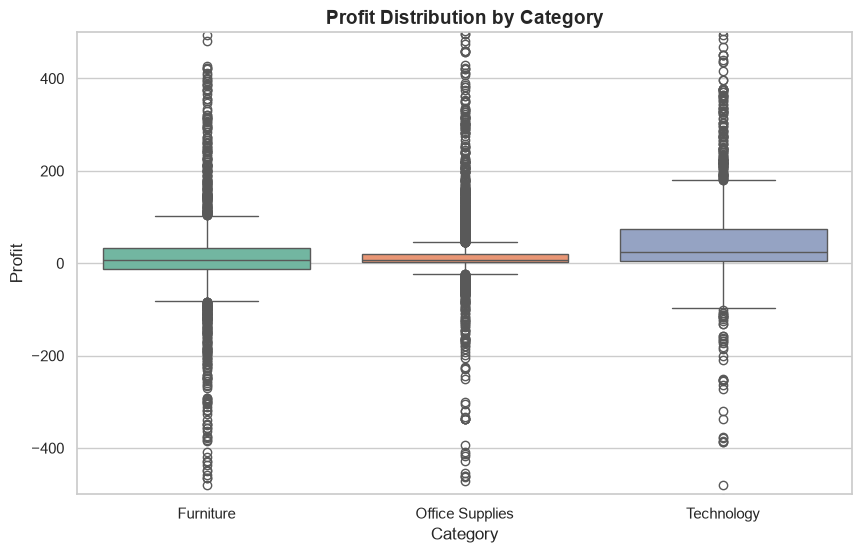

In [28]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df_raw['Order Date'] = pd.to_datetime(df_raw['Order Date'])

plt.style.use('ggplot')
sns.set_theme(style="whitegrid")

# ==========================================
# 1. Bar Chart: Top 10 Sub-Categories by Sales
# ==========================================
plt.figure(figsize=(12, 6))
top_sub_cat = df_raw.groupby('Sub-Category')['Sales'].sum().nlargest(10).sort_values()
top_sub_cat.plot(kind='barh', color='teal')
plt.title('Top 10 Sub-Categories by Total Sales', fontsize=14, fontweight='bold')
plt.xlabel('Total Sales')
plt.ylabel('Sub-Category')
plt.show()

# ==========================================
# 2. Line Chart: Monthly Sales Trend Over Time
# ==========================================
plt.figure(figsize=(14, 6))
monthly_sales = df_raw.set_index('Order Date').resample('ME')['Sales'].sum()
monthly_sales.plot(kind='line', marker='o', color='blue', linewidth=2)
plt.title('Monthly Sales Trend', fontsize=14, fontweight='bold')
plt.xlabel('Date')
plt.ylabel('Total Sales')
plt.show()

# ==========================================
# 3. Boxplot: Profit Distribution by Category
# ==========================================
plt.figure(figsize=(10, 6))
sns.boxplot(data=df_raw, x='Category', y='Profit', palette='Set2')
plt.title('Profit Distribution by Category', fontsize=14, fontweight='bold')
plt.ylim(-500, 500) 
plt.show()

In [29]:
loss_orders = df[df["Profit"] < 0]

In [30]:
same_day_west = df[(df["Ship Mode"] == "Same Day") & (df["Region"] == "West")]

In [31]:
df.loc[df["Profit"] < 0, ["Order ID", "Category", "Sub-Category", "Profit"]]

,Order ID,Category,Sub-Category,Profit
3,US-2017-108966,Furniture,Tables,-383.0310
14,US-2017-118983,Office Supplies,Appliances,-123.8580
15,US-2017-118983,Office Supplies,Binders,-3.8160
23,US-2019-156909,Furniture,Chairs,-1.0196
27,US-2017-150630,Furniture,Bookcases,-1665.0522
...,...,...,...,...
9920,CA-2018-149272,Office Supplies,Binders,-35.8176
9921,CA-2016-111360,Office Supplies,Binders,-4.5936
9931,CA-2017-104948,Furniture,Bookcases,-40.1960
9937,CA-2018-164889,Furniture,Tables,-1.7772


In [32]:
df.iloc[:5, :3]

,Row ID,Order ID,Order Date
0,1,CA-2018-152156,2018-11-08
1,2,CA-2018-152156,2018-11-08
2,3,CA-2018-138688,2018-06-12
3,4,US-2017-108966,2017-10-11
4,5,US-2017-108966,2017-10-11


In [33]:
columns_to_drop = ["Unnamed: 0", "Row ID"]

existing_cols_to_drop = [col for col in columns_to_drop if col in df_raw.columns]

if existing_cols_to_drop:
    df_raw = df_raw.drop(columns=existing_cols_to_drop)
    print(f"Dropped columns: {existing_cols_to_drop}")
else:
    print("Columns not found, skipping drop.")

df_raw.info(memory_usage='deep')

Dropped columns: ['Row ID']
<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 20 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Order ID        9994 non-null   str           
 1   Order Date      9994 non-null   datetime64[us]
 2   Ship Date       9994 non-null   datetime64[us]
 3   Ship Mode       9994 non-null   str           
 4   Customer ID     9994 non-null   str           
 5   Customer Name   9994 non-null   str           
 6   Segment         9994 non-null   str           
 7   Country/Region  9994 non-null   str           
 8   City            9994 non-null   str           
 9   State           9994 non-null   str           
 10  Postal Code     9994 non-null   object        
 11  Region          9994 non-null   str           
 12  Product ID      9994 non-null   str           
 13  Category        9994 non-null   str           
 14  Sub-Category    9994 non-null   str    

In [34]:
string_cols = df_raw.select_dtypes('str').columns.tolist()

for col in string_cols:
    df_raw[col] = df_raw[col].str.strip().str.title()

In [35]:
print("Shape:", df_raw.shape)
df_raw.head()

Shape: (9994, 20)


,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,Ca-2018-152156,2018-11-08,2018-11-11,Second Class,Cg-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,Fur-Bo-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,Ca-2018-152156,2018-11-08,2018-11-11,Second Class,Cg-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,Fur-Ch-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,Ca-2018-138688,2018-06-12,2018-06-16,Second Class,Dv-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036.0,West,Off-La-10000240,Office Supplies,Labels,Self-Adhesive Address Labels For Typewriters B...,14.6200,2,0.00,6.8714
3,Us-2017-108966,2017-10-11,2017-10-18,Standard Class,So-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,Fur-Ta-10000577,Furniture,Tables,Bretford Cr4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,Us-2017-108966,2017-10-11,2017-10-18,Standard Class,So-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,Off-St-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [36]:
df_raw.tail()

,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
9989,Ca-2016-110422,2016-01-21,2016-01-23,Second Class,Tb-21400,Tom Boeckenhauer,Consumer,United States,Miami,Florida,33180.0,South,Fur-Fu-10001889,Furniture,Furnishings,Ultra Door Pull Handle,25.248,3,0.2,4.1028
9990,Ca-2019-121258,2019-02-26,2019-03-03,Standard Class,Db-13060,Dave Brooks,Consumer,United States,Costa Mesa,California,92627.0,West,Fur-Fu-10000747,Furniture,Furnishings,Tenex B1-Re Series Chair Mats For Low Pile Car...,91.960,2,0.0,15.6332
9991,Ca-2019-121258,2019-02-26,2019-03-03,Standard Class,Db-13060,Dave Brooks,Consumer,United States,Costa Mesa,California,92627.0,West,Tec-Ph-10003645,Technology,Phones,Aastra 57I Voip Phone,258.576,2,0.2,19.3932
9992,Ca-2019-121258,2019-02-26,2019-03-03,Standard Class,Db-13060,Dave Brooks,Consumer,United States,Costa Mesa,California,92627.0,West,Off-Pa-10004041,Office Supplies,Paper,"It'S Hot Message Books With Stickers, 2 3/4"" X 5""",29.600,4,0.0,13.3200
9993,Ca-2019-119914,2019-05-04,2019-05-09,Second Class,Cc-12220,Chris Cortes,Consumer,United States,Westminster,California,92683.0,West,Off-Ap-10002684,Office Supplies,Appliances,"Acco 7-Outlet Masterpiece Power Center, Wihtou...",243.160,2,0.0,72.9480


In [37]:
print(df_raw.columns.tolist())
df_raw.info()

['Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country/Region', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']
<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 20 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Order ID        9994 non-null   str           
 1   Order Date      9994 non-null   datetime64[us]
 2   Ship Date       9994 non-null   datetime64[us]
 3   Ship Mode       9994 non-null   str           
 4   Customer ID     9994 non-null   str           
 5   Customer Name   9994 non-null   str           
 6   Segment         9994 non-null   str           
 7   Country/Region  9994 non-null   str           
 8   City            9994 non-null   str           
 9   State           9994 non-null   str           
 10  Postal Code     99

In [38]:
df_raw[["Sales", "Quantity", "Discount", "Profit"]].describe()

,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000
mean,229.858001,3.789574,0.156203,28.656896
std,623.245101,2.225110,0.206452,234.260108
min,0.444000,1.000000,0.000000,-6599.978000
25%,17.280000,2.000000,0.000000,1.728750
50%,54.490000,3.000000,0.200000,8.666500
75%,209.940000,5.000000,0.200000,29.364000
max,22638.480000,14.000000,0.800000,8399.976000


In [39]:
df_raw.describe(include="str")

,Order ID,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,State,Region,Product ID,Category,Sub-Category,Product Name
count,9994,9994,9994,9994,9994,9994,9994,9994,9994,9994,9994,9994,9994
unique,5009,4,793,793,3,1,531,49,4,1862,3,17,1850
top,Ca-2019-100111,Standard Class,Wb-21850,William Brown,Consumer,United States,New York City,California,West,Off-Pa-10001970,Office Supplies,Binders,Staple Envelope
freq,14,5968,37,37,5191,9994,915,2001,3203,19,6026,1523,48


In [40]:
df_loss = df_raw[(df_raw["Profit"]<0) & (df_raw["Discount"] == 0.8)]
df_loss

,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
14,Us-2017-118983,2017-11-22,2017-11-26,Standard Class,Hp-14815,Harold Pawlan,Home Office,United States,Fort Worth,Texas,76106.0,Central,Off-Ap-10002311,Office Supplies,Appliances,Holmes Replacement Filter For Hepa Air Cleaner...,68.810,5,0.8,-123.8580
15,Us-2017-118983,2017-11-22,2017-11-26,Standard Class,Hp-14815,Harold Pawlan,Home Office,United States,Fort Worth,Texas,76106.0,Central,Off-Bi-10000756,Office Supplies,Binders,Storex Duratech Recycled Plastic Frosted Binders,2.544,3,0.8,-3.8160
75,Us-2019-118038,2019-12-09,2019-12-11,First Class,Kb-16600,Ken Brennan,Corporate,United States,Houston,Texas,77041.0,Central,Off-Bi-10004182,Office Supplies,Binders,Economy Binders,1.248,3,0.8,-1.9344
101,Ca-2018-158568,2018-08-29,2018-09-02,Standard Class,Rb-19465,Rick Bensley,Home Office,United States,Chicago,Illinois,60610.0,Central,Off-Bi-10002609,Office Supplies,Binders,Avery Hidden Tab Dividers For Binding Systems,1.788,3,0.8,-3.0396
169,Ca-2016-139892,2016-09-08,2016-09-12,Standard Class,Bm-11140,Becky Martin,Consumer,United States,San Antonio,Texas,78207.0,Central,Off-Ap-10002518,Office Supplies,Appliances,Kensington 7 Outlet Masterpiece Power Center,177.980,5,0.8,-453.8490
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9794,Ca-2016-127166,2016-05-21,2016-05-23,Second Class,Kh-16360,Katherine Hughes,Consumer,United States,Houston,Texas,77070.0,Central,Off-Bi-10000977,Office Supplies,Binders,Ibico Plastic Spiral Binding Combs,18.240,3,0.8,-31.0080
9795,Ca-2018-125920,2018-05-21,2018-05-28,Standard Class,Sh-19975,Sally Hughsby,Corporate,United States,Chicago,Illinois,60610.0,Central,Off-Bi-10003429,Office Supplies,Binders,"Cardinal Holdit! Binder Insert Strips,Extra St...",3.798,3,0.8,-5.8869
9808,Ca-2019-145093,2019-07-21,2019-07-26,Standard Class,Pt-19090,Pete Takahito,Consumer,United States,Chicago,Illinois,60623.0,Central,Off-Bi-10001116,Office Supplies,Binders,"Wilson Jones 1"" Hanging Dubllock Ring Binders",2.112,2,0.8,-3.3792
9835,Ca-2018-126627,2018-10-10,2018-10-12,First Class,Wb-21850,William Brown,Consumer,United States,La Porte,Texas,77571.0,Central,Off-Bi-10001597,Office Supplies,Binders,"Wilson Jones Ledger-Size, Piano-Hinge Binder, ...",16.392,2,0.8,-26.2272


In [41]:
print(df_raw["Region"].value_counts())
print()
print(df_raw["Segment"].value_counts())
print()
print(df_raw["Ship Mode"].value_counts())

Region
West       3203
East       2848
Central    2323
South      1620
Name: count, dtype: int64

Segment
Consumer       5191
Corporate      3020
Home Office    1783
Name: count, dtype: int64

Ship Mode
Standard Class    5968
Second Class      1945
First Class       1538
Same Day           543
Name: count, dtype: int64


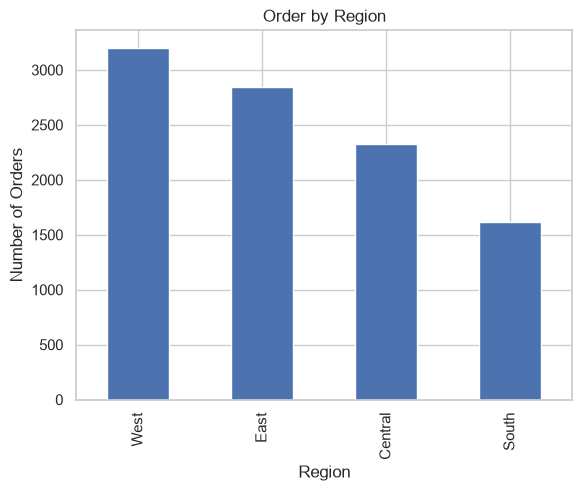

In [42]:
df_raw["Region"].value_counts().plot(kind='bar')
plt.title("Order by Region")
plt.xlabel("Region")
plt.ylabel("Number of Orders")
plt.show()

In [43]:
print(df_raw[["Sales", "Profit"]].describe())


              Sales       Profit
count   9994.000000  9994.000000
mean     229.858001    28.656896
std      623.245101   234.260108
min        0.444000 -6599.978000
25%       17.280000     1.728750
50%       54.490000     8.666500
75%      209.940000    29.364000
max    22638.480000  8399.976000


In [44]:
print(df_raw["Category"].value_counts())


Category
Office Supplies    6026
Furniture          2121
Technology         1847
Name: count, dtype: int64


In [45]:
print(df_raw["Ship Mode"].value_counts(normalize=True)*100)


Ship Mode
Standard Class    59.715829
Second Class      19.461677
First Class       15.389234
Same Day           5.433260
Name: proportion, dtype: float64


In [46]:
print(f"Minimum Discount: {df_raw["Discount"].min()} - Maximum Discount: {df_raw["Discount"].max()}")


Minimum Discount: 0.0 - Maximum Discount: 0.8


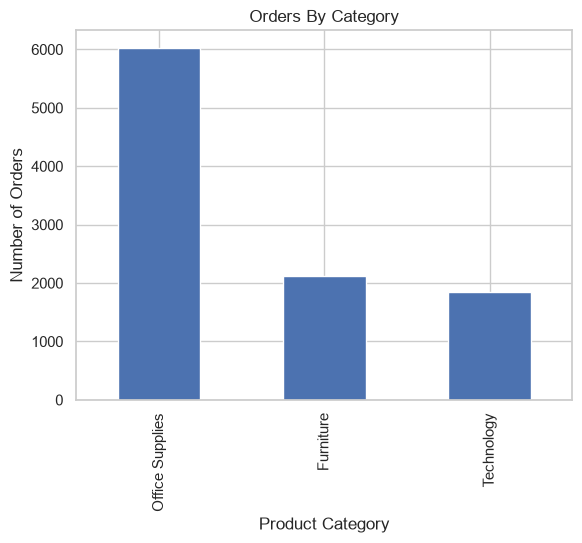

In [47]:
df_raw["Category"].value_counts().plot(kind='bar')
plt.title("Orders By Category")
plt.xlabel("Product Category")
plt.ylabel("Number of Orders")
plt.show()

In [48]:
df_raw.info(memory_usage='deep')

<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 20 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Order ID        9994 non-null   str           
 1   Order Date      9994 non-null   datetime64[us]
 2   Ship Date       9994 non-null   datetime64[us]
 3   Ship Mode       9994 non-null   str           
 4   Customer ID     9994 non-null   str           
 5   Customer Name   9994 non-null   str           
 6   Segment         9994 non-null   str           
 7   Country/Region  9994 non-null   str           
 8   City            9994 non-null   str           
 9   State           9994 non-null   str           
 10  Postal Code     9994 non-null   object        
 11  Region          9994 non-null   str           
 12  Product ID      9994 non-null   str           
 13  Category        9994 non-null   str           
 14  Sub-Category    9994 non-null   str           
 15  Product Name   

In [49]:
df_raw[["Order Date", "Ship Date"]] = df_raw[["Order Date", "Ship Date"]].apply(pd.to_datetime)
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 20 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Order ID        9994 non-null   str           
 1   Order Date      9994 non-null   datetime64[us]
 2   Ship Date       9994 non-null   datetime64[us]
 3   Ship Mode       9994 non-null   str           
 4   Customer ID     9994 non-null   str           
 5   Customer Name   9994 non-null   str           
 6   Segment         9994 non-null   str           
 7   Country/Region  9994 non-null   str           
 8   City            9994 non-null   str           
 9   State           9994 non-null   str           
 10  Postal Code     9994 non-null   object        
 11  Region          9994 non-null   str           
 12  Product ID      9994 non-null   str           
 13  Category        9994 non-null   str           
 14  Sub-Category    9994 non-null   str           
 15  Product Name   

In [87]:
str_cols = df_raw.select_dtypes(include=['object', 'str']).columns.tolist()

for col in str_cols:
    if df_raw[col].nunique() <= 50:
        df_raw[col] = df_raw[col].astype("category")

df_raw.info()

<class 'pandas.DataFrame'>
Index: 9993 entries, 0 to 9993
Data columns (total 20 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Order ID        9993 non-null   str           
 1   Order Date      9993 non-null   datetime64[us]
 2   Ship Date       9993 non-null   datetime64[us]
 3   Ship Mode       9993 non-null   category      
 4   Customer ID     9993 non-null   str           
 5   Customer Name   9993 non-null   str           
 6   Segment         9993 non-null   category      
 7   Country/Region  9993 non-null   category      
 8   City            9993 non-null   str           
 9   State           9993 non-null   category      
 10  Postal Code     9993 non-null   str           
 11  Region          9993 non-null   category      
 12  Product ID      9993 non-null   str           
 13  Category        9993 non-null   category      
 14  Sub-Category    9993 non-null   category      
 15  Product Name    9993

In [51]:
print(df_raw.memory_usage(deep=True))
print(df_raw.info(memory_usage="deep"))

Index                132
Order ID          221118
Order Date         79952
Ship Date          79952
Ship Mode          10072
Customer ID       161154
Customer Name     210820
Segment            10047
Country/Region     10016
City              174453
State              10823
Postal Code       320358
Region             10047
Product ID        231112
Category           10053
Sub-Category       10261
Product Name      450746
Sales              79952
Quantity           79952
Discount           79952
Profit             79952
dtype: int64
<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 20 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Order ID        9994 non-null   str           
 1   Order Date      9994 non-null   datetime64[us]
 2   Ship Date       9994 non-null   datetime64[us]
 3   Ship Mode       9994 non-null   category      
 4   Customer ID     9994 non-null   str           
 5

In [52]:

df_raw["Postal Code"] = df_raw["Postal Code"].astype("str")


df_raw["Postal Code"].isnull().sum()


df_raw[df_raw["Postal Code"].isnull() == True][["Country/Region", "City", "State", "Region"]]


df_raw["Postal Code"] = df_raw["Postal Code"].fillna("05401")
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 20 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Order ID        9994 non-null   str           
 1   Order Date      9994 non-null   datetime64[us]
 2   Ship Date       9994 non-null   datetime64[us]
 3   Ship Mode       9994 non-null   category      
 4   Customer ID     9994 non-null   str           
 5   Customer Name   9994 non-null   str           
 6   Segment         9994 non-null   category      
 7   Country/Region  9994 non-null   category      
 8   City            9994 non-null   str           
 9   State           9994 non-null   category      
 10  Postal Code     9994 non-null   str           
 11  Region          9994 non-null   category      
 12  Product ID      9994 non-null   str           
 13  Category        9994 non-null   category      
 14  Sub-Category    9994 non-null   category      
 15  Product Name   

In [53]:
df_raw.duplicated().sum()

np.int64(1)

In [54]:
df_raw = df_raw.drop_duplicates()

In [55]:
df_raw.shape

(9993, 20)

In [56]:
df_raw.duplicated(subset=["Order ID", "Product ID"]).sum()

np.int64(7)

In [57]:
order_product_duplicates = df_raw[df_raw.duplicated(subset=["Order ID", "Product ID"], keep=False) == True].sort_values("Order ID")

In [58]:
order_product_duplicates["Unit Price"] = order_product_duplicates["Sales"] / order_product_duplicates["Quantity"]
order_product_duplicates["Unit Profit"] = order_product_duplicates["Profit"] / order_product_duplicates["Quantity"]

In [59]:
df_raw.duplicated(subset=["Customer ID", "Order Date"], keep=False).sum()

np.int64(7474)

In [60]:
duplicate_count = df_raw.duplicated(subset=["Customer ID", "Order Date"], keep=False).sum()
print(f"Rows with same customer on the same day: {duplicate_count}")

Rows with same customer on the same day: 7474


In [61]:
category_col = df_raw.select_dtypes('category').columns.tolist()

In [62]:
for col in category_col:
    print(col, "->\n", df_raw[col].unique(), "\n" + "-"*50)

Ship Mode ->
 ['Second Class', 'Standard Class', 'First Class', 'Same Day']
Categories (4, str): ['First Class', 'Same Day', 'Second Class', 'Standard Class'] 
--------------------------------------------------
Segment ->
 ['Consumer', 'Corporate', 'Home Office']
Categories (3, str): ['Consumer', 'Corporate', 'Home Office'] 
--------------------------------------------------
Country/Region ->
 ['United States']
Categories (1, str): ['United States'] 
--------------------------------------------------
State ->
 ['Kentucky', 'California', 'Florida', 'North Carolina', 'Washington', ..., 'South Dakota', 'Idaho', 'North Dakota', 'Wyoming', 'West Virginia']
Length: 49
Categories (49, str): ['Alabama', 'Arizona', 'Arkansas', 'California', ..., 'Washington', 'West Virginia', 'Wisconsin', 'Wyoming'] 
--------------------------------------------------
Region ->
 ['South', 'West', 'Central', 'East']
Categories (4, str): ['Central', 'East', 'South', 'West'] 
---------------------------------------

In [63]:
df["Segment"] = df["Segment"].astype(str).str.strip().str.title()
df["Segment"].unique()

<ArrowStringArray>
['Consumer', 'Corporate', 'Home Office']
Length: 3, dtype: str

In [64]:
df_raw["Segment"].unique()

['Consumer', 'Corporate', 'Home Office']
Categories (3, str): ['Consumer', 'Corporate', 'Home Office']

In [65]:
df_raw["Segment"] = df_raw["Segment"].str.replace("Consumer ", "Consumer", regex=False)

In [66]:
print("After:", df_raw["Segment"].unique())

After: <ArrowStringArray>
['Consumer', 'Corporate', 'Home Office']
Length: 3, dtype: str


In [67]:
print("Minimum Discount:", df_raw["Discount"].min())
print("Maximum Discount:", df_raw["Discount"].max())

Minimum Discount: 0.0
Maximum Discount: 0.8


In [68]:
invalid_discounts = df_raw[(df_raw["Discount"] < 0) | (df_raw["Discount"] > 1)]

print(f"\nNumber of rows with invalid discount values: {len(invalid_discounts)}")


Number of rows with invalid discount values: 0


In [69]:
if len(invalid_discounts) > 0:
    display(invalid_discounts[["Order ID", "Discount"]])

In [70]:
import seaborn as sns

C:\Users\اذكر الله\AppData\Local\Temp\ipykernel_15244\788736324.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=profitable_orders, x='Category', y='Profit', ax=axes[0], palette='Greens')
C:\Users\اذكر الله\AppData\Local\Temp\ipykernel_15244\788736324.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=loss_making_orders, x='Category', y='Profit', ax=axes[1], palette='Reds')


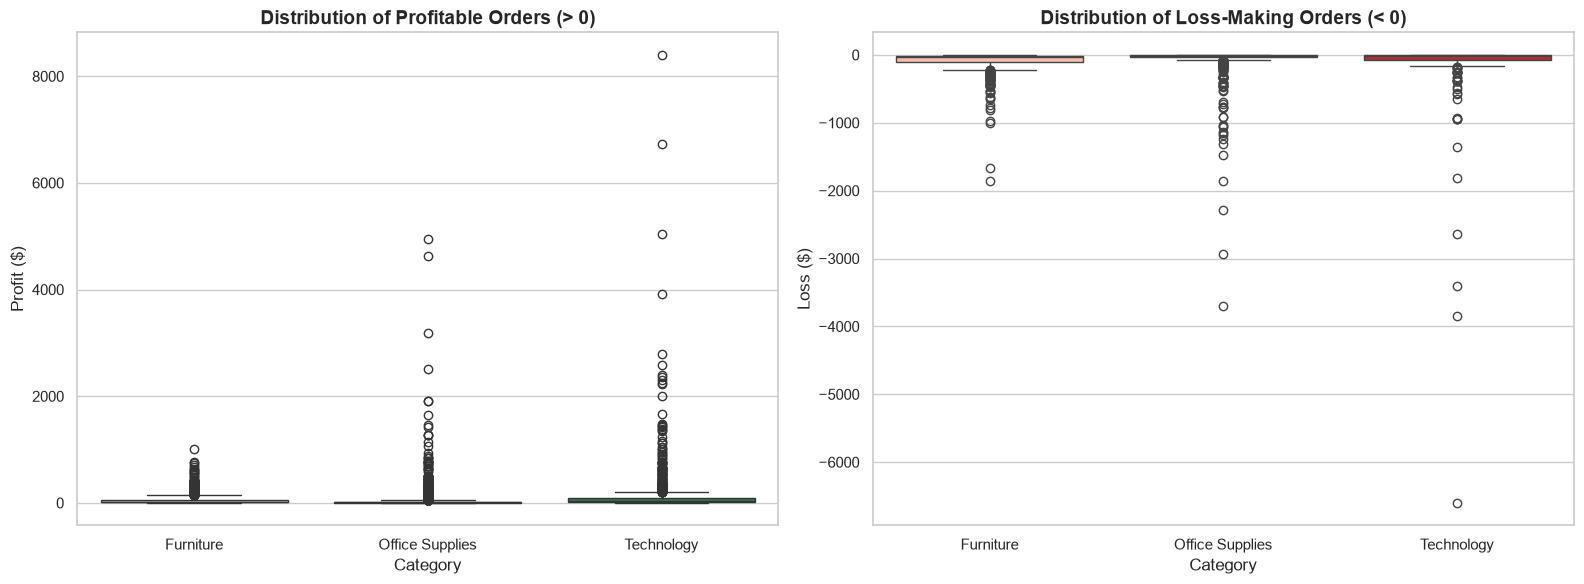

In [71]:
import matplotlib.pyplot as plt
import seaborn as sns

profitable_orders = df_raw[df_raw["Profit"] > 0]
loss_making_orders = df_raw[df_raw["Profit"] < 0]

# 2. إعداد مساحة الرسم البياني لتشمل رسمتين جنباً إلى جنب (1 row, 2 columns)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.boxplot(data=profitable_orders, x='Category', y='Profit', ax=axes[0], palette='Greens')
axes[0].set_title('Distribution of Profitable Orders (> 0)', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Profit ($)')

sns.boxplot(data=loss_making_orders, x='Category', y='Profit', ax=axes[1], palette='Reds')
axes[1].set_title('Distribution of Loss-Making Orders (< 0)', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Loss ($)')

plt.tight_layout()
plt.show()

In [72]:
consumer_mask = ((df_raw["Segment"] == 'Consumer') & (df_raw["Profit"] >= 0))
corporate_mask = ((df_raw["Segment"] == 'Corporate') & (df_raw["Profit"] >= 0))
home_office_mask = ((df_raw["Segment"] == 'Home Office') & (df_raw["Profit"] >= 0))

consumer_sales = df_raw[consumer_mask]
corporate_sales = df_raw[corporate_mask]
home_office_sales = df_raw[home_office_mask]

In [73]:
print("Shapes (Consumer, Corporate, Home Office):")
print(consumer_sales.shape, corporate_sales.shape, home_office_sales.shape)

Shapes (Consumer, Corporate, Home Office):
(4188, 20) (2464, 20) (1471, 20)


In [74]:
missing_data = consumer_sales.isnull().sum()
print(missing_data[missing_data > 0])

Series([], dtype: int64)


In [75]:
print("\n--- Consumer Sales Description ---")
display(consumer_sales.describe())

print("\n--- Sanity Check (Minimum Profit in Home Office) ---")
print("Min Profit:", home_office_sales["Profit"].min())


--- Consumer Sales Description ---


,Order Date,Ship Date,Sales,Quantity,Discount,Profit
count,4188,4188,4188.000000,4188.000000,4188.000000,4188.000000
mean,2018-04-25 21:50:42.979942,2018-04-29 20:31:17.363896,218.291571,3.789398,0.082175,52.307765
min,2016-01-03 00:00:00,2016-01-07 00:00:00,1.240000,1.000000,0.000000,0.000000
25%,2017-05-12 00:00:00,2017-05-17 18:00:00,17.920000,2.000000,0.000000,5.127800
50%,2018-06-17 00:00:00,2018-06-18 00:00:00,50.336000,3.000000,0.000000,12.888400
75%,2019-05-14 00:00:00,2019-05-18 00:00:00,191.970000,5.000000,0.200000,38.593800
max,2019-12-30 00:00:00,2020-01-04 00:00:00,13999.960000,14.000000,0.400000,6719.980800
std,NaN,NaN,597.694669,2.242108,0.099703,214.957972



--- Sanity Check (Minimum Profit in Home Office) ---
Min Profit: 0.0


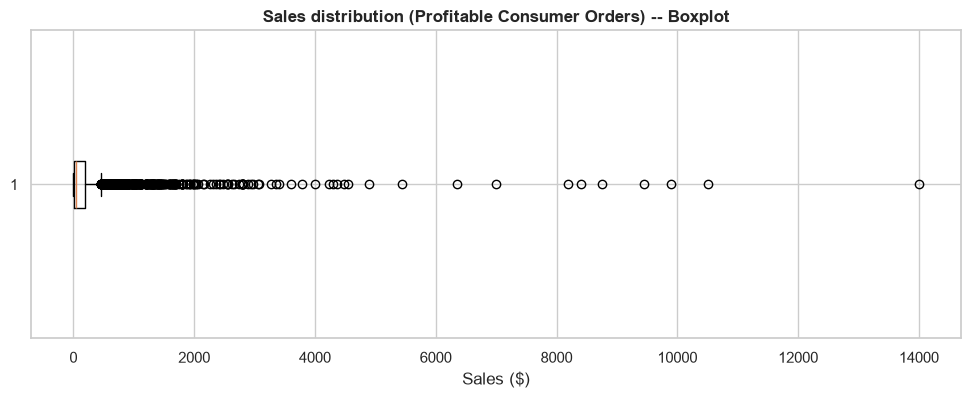

In [76]:
plt.figure(figsize=(12, 4))
plt.boxplot(consumer_sales["Sales"], orientation="horizontal")
plt.title("Sales distribution (Profitable Consumer Orders) -- Boxplot", fontweight='bold')
plt.xlabel("Sales ($)")
plt.show()

In [77]:
q1 = consumer_sales["Sales"].quantile(0.25)
q3 = consumer_sales["Sales"].quantile(0.75)
iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

outliers = consumer_sales[(consumer_sales["Sales"] < lower_bound) | (consumer_sales["Sales"] > upper_bound)]

print(f"Sales outlier bounds: [{lower_bound:.2f}, {upper_bound:.2f}]")
print("Number of Sales outliers:", len(outliers))

Sales outlier bounds: [-243.16, 453.05]
Number of Sales outliers: 497


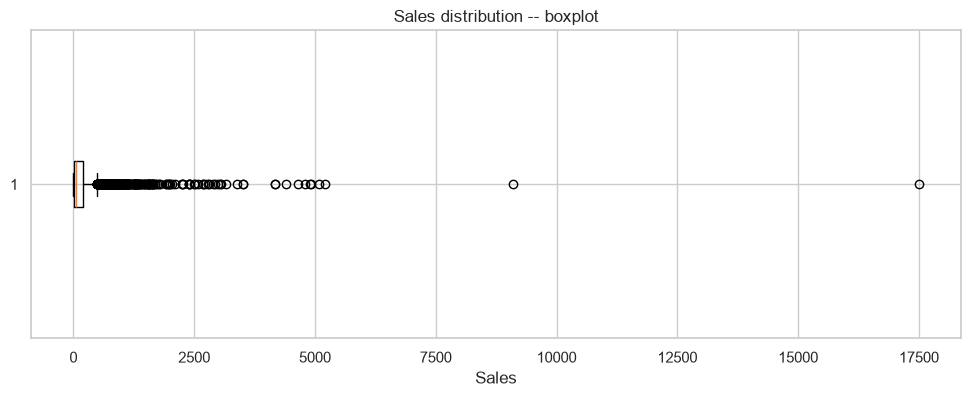

In [78]:
plt.figure(figsize=(12, 4))
plt.boxplot(corporate_sales["Sales"], orientation="horizontal")
plt.title("Sales distribution -- boxplot")
plt.xlabel("Sales")
plt.show()

In [79]:
# IQR method: flag numeric outliers beyond 1.5x the interquartile range
q1 = corporate_sales["Sales"].quantile(0.25)
q3 = corporate_sales["Sales"].quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

outliers = corporate_sales[(corporate_sales["Sales"] < lower_bound) | (corporate_sales["Sales"] > upper_bound)]
print(f"Sales outlier bounds: [{lower_bound:.2f}, {upper_bound:.2f}]")
print("Number of Sales outliers:", len(outliers))

Sales outlier bounds: [-261.78, 485.02]
Number of Sales outliers: 308


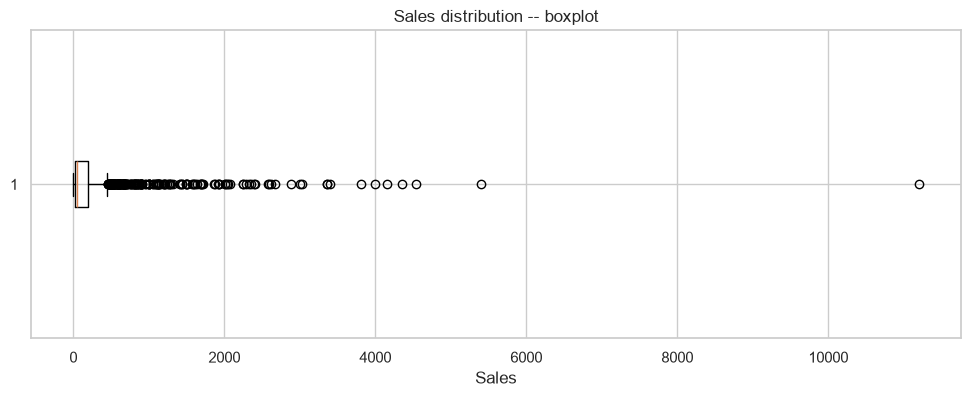

In [80]:
# Visual check for outliers in Sales using a boxplot
plt.figure(figsize=(12, 4))
plt.boxplot(home_office_sales["Sales"], orientation="horizontal")
plt.title("Sales distribution -- boxplot")
plt.xlabel("Sales")
plt.show()

In [81]:
# IQR method: flag numeric outliers beyond 1.5x the interquartile range
q1 = home_office_sales["Sales"].quantile(0.25)
q3 = home_office_sales["Sales"].quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

outliers = home_office_sales[(home_office_sales["Sales"] < lower_bound) | (home_office_sales["Sales"] > upper_bound)]
print(f"Sales outlier bounds: [{lower_bound:.2f}, {upper_bound:.2f}]")
print("Number of Sales outliers:", len(outliers))

Sales outlier bounds: [-242.10, 452.03]
Number of Sales outliers: 191


In [82]:
df_raw.isnull().sum()

Order ID          0
Order Date        0
Ship Date         0
Ship Mode         0
Customer ID       0
Customer Name     0
Segment           0
Country/Region    0
City              0
State             0
Postal Code       0
Region            0
Product ID        0
Category          0
Sub-Category      0
Product Name      0
Sales             0
Quantity          0
Discount          0
Profit            0
dtype: int64

In [83]:
df_raw[df_raw["Profit"] < 0]["Discount"].max()

np.float64(0.8)

In [84]:
df_raw.info()

<class 'pandas.DataFrame'>
Index: 9993 entries, 0 to 9993
Data columns (total 20 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Order ID        9993 non-null   str           
 1   Order Date      9993 non-null   datetime64[us]
 2   Ship Date       9993 non-null   datetime64[us]
 3   Ship Mode       9993 non-null   category      
 4   Customer ID     9993 non-null   str           
 5   Customer Name   9993 non-null   str           
 6   Segment         9993 non-null   str           
 7   Country/Region  9993 non-null   category      
 8   City            9993 non-null   str           
 9   State           9993 non-null   category      
 10  Postal Code     9993 non-null   str           
 11  Region          9993 non-null   category      
 12  Product ID      9993 non-null   str           
 13  Category        9993 non-null   category      
 14  Sub-Category    9993 non-null   category      
 15  Product Name    9993

In [85]:
df_raw.head()

,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,Ca-2018-152156,2018-11-08,2018-11-11,Second Class,Cg-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,Fur-Bo-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,Ca-2018-152156,2018-11-08,2018-11-11,Second Class,Cg-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,Fur-Ch-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,Ca-2018-138688,2018-06-12,2018-06-16,Second Class,Dv-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036.0,West,Off-La-10000240,Office Supplies,Labels,Self-Adhesive Address Labels For Typewriters B...,14.6200,2,0.00,6.8714
3,Us-2017-108966,2017-10-11,2017-10-18,Standard Class,So-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,Fur-Ta-10000577,Furniture,Tables,Bretford Cr4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,Us-2017-108966,2017-10-11,2017-10-18,Standard Class,So-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,Off-St-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [86]:
df_raw.to_parquet("Sample_Superstore_2019_Clean.parquet", index=False, engine='pyarrow')